<a href="https://colab.research.google.com/github/geRSun1/Computer_version/blob/main/CV_buoi6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bai 1

Sinh khoảng 200 điểm 2 chiều tương quan (ví dụ một đám mây điểm dẹt theo một hướng chéo).

Tự tính: vector trung bình μ, ma trận hiệp phương sai (covariance matrix) Σ = (1/N) Σ (xi−μ)(xi−μ)
T
, rồi trị riêng
(eigenvalues) và vector riêng (eigenvectors) của Σ ( np.linalg.eigh )

Vector trung binh mu:
[-0.0793788  -0.03860784]

Ma tran covariance Sigma:
[[8.2652171  5.63441698]
 [5.63441698 3.86605131]]

Eigenvalues:
[12.11417284  0.01709557]

Eigenvectors (moi cot la mot vector rieng):
[[-0.82572855  0.5640677 ]
 [-0.5640677  -0.82572855]]


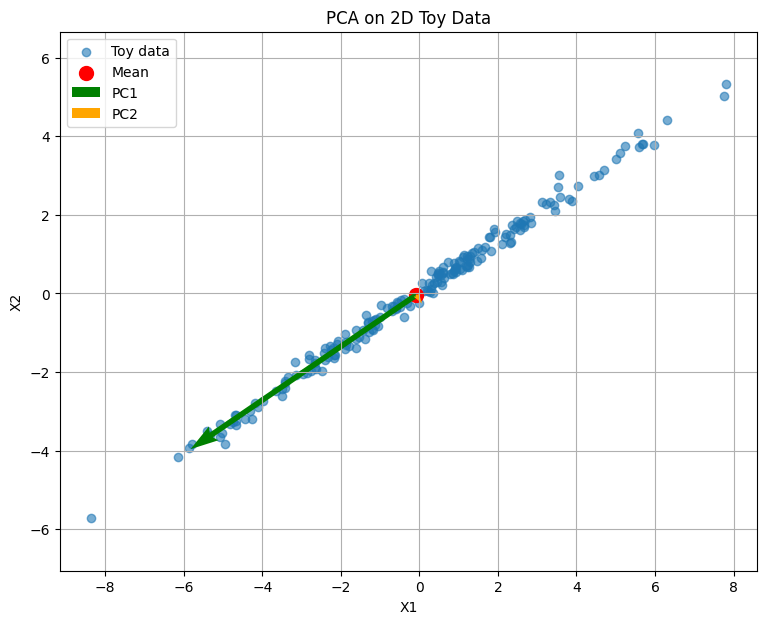


Explained variance ratio:
[0.99859078 0.00140922]
PC1 explains 99.86% of the variance


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from PIL import Image

# ==========================================
# 1. TAO TOY DATA: 200 diem du lieu 2 chieu
# ==========================================
np.random.seed(42)

N = 200

# Tao du lieu co dang dam may keo dai theo huong cheo
t = np.random.randn(N)
noise = np.random.randn(N) * 0.5

X = np.column_stack([
    3 * t + noise,
    2 * t + noise
])

# ==========================================
# 2. TINH VECTOR TRUNG BINH
# ==========================================
mu = np.mean(X, axis=0)

# Tru vector trung binh khoi tung diem
X_centered = X - mu

print("Vector trung binh mu:")
print(mu)

# ==========================================
# 3. TINH MA TRAN HIEP PHUONG SAI
# ==========================================
Sigma = (X_centered.T @ X_centered) / N

print("\nMa tran covariance Sigma:")
print(Sigma)

# ==========================================
# 4. TINH TRI RIENG VA VECTOR RIENG
# ==========================================
eigenvalues, eigenvectors = np.linalg.eigh(Sigma)

# Sap xep theo tri rieng giam dan
idx = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("\nEigenvalues:")
print(eigenvalues)

print("\nEigenvectors (moi cot la mot vector rieng):")
print(eigenvectors)

# ==========================================
# 5. VE DU LIEU VA HAI TRUC CHINH
# ==========================================
plt.figure(figsize=(9, 7))

plt.scatter(
    X[:, 0], X[:, 1],
    alpha=0.6, label="Toy data"
)

# Danh dau vector trung binh
plt.scatter(
    mu[0], mu[1],
    color="red", s=100, label="Mean"
)

# Ve cac vector rieng tai tam dam may
for i in range(2):
    v = eigenvectors[:, i]
    length = 2 * np.sqrt(eigenvalues[i])

    plt.quiver(
        mu[0], mu[1],
        v[0] * length,
        v[1] * length,
        angles="xy",
        scale_units="xy",
        scale=1,
        color=["green", "orange"][i],
        width=0.008,
        label=f"PC{i+1}"
    )

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("PCA on 2D Toy Data")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

# ==========================================
# 6. TINH TY LE PHUONG SAI DUOC GIAI THICH
# ==========================================
explained_ratio = eigenvalues / np.sum(eigenvalues)

print("\nExplained variance ratio:")
print(explained_ratio)

print(
    f"PC1 explains {explained_ratio[0] * 100:.2f}% "
    "of the variance"
)


In [ ]:
Bai 2
Tải một tập ảnh khuôn mặt (ví dụ sklearn.datasets.fetch_olivetti_faces hoặc fetch_lfw_people ). Mỗi
ảnh M×M được TRẢI thành một vector M2 chiều.
Tính và hiển thị khuôn mặt trung bình μ (mean face).
Chạy PCA ( sklearn.decomposition.PCA ) và hiển thị vài chục vector riêng đầu tiên dưới dạng ảnh — đó chính là
các eigenfaces. Chúng trông như thế nào?


X shape: (400, 4096)


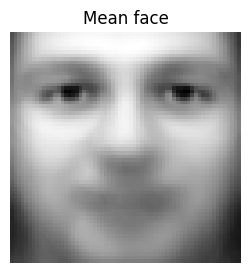

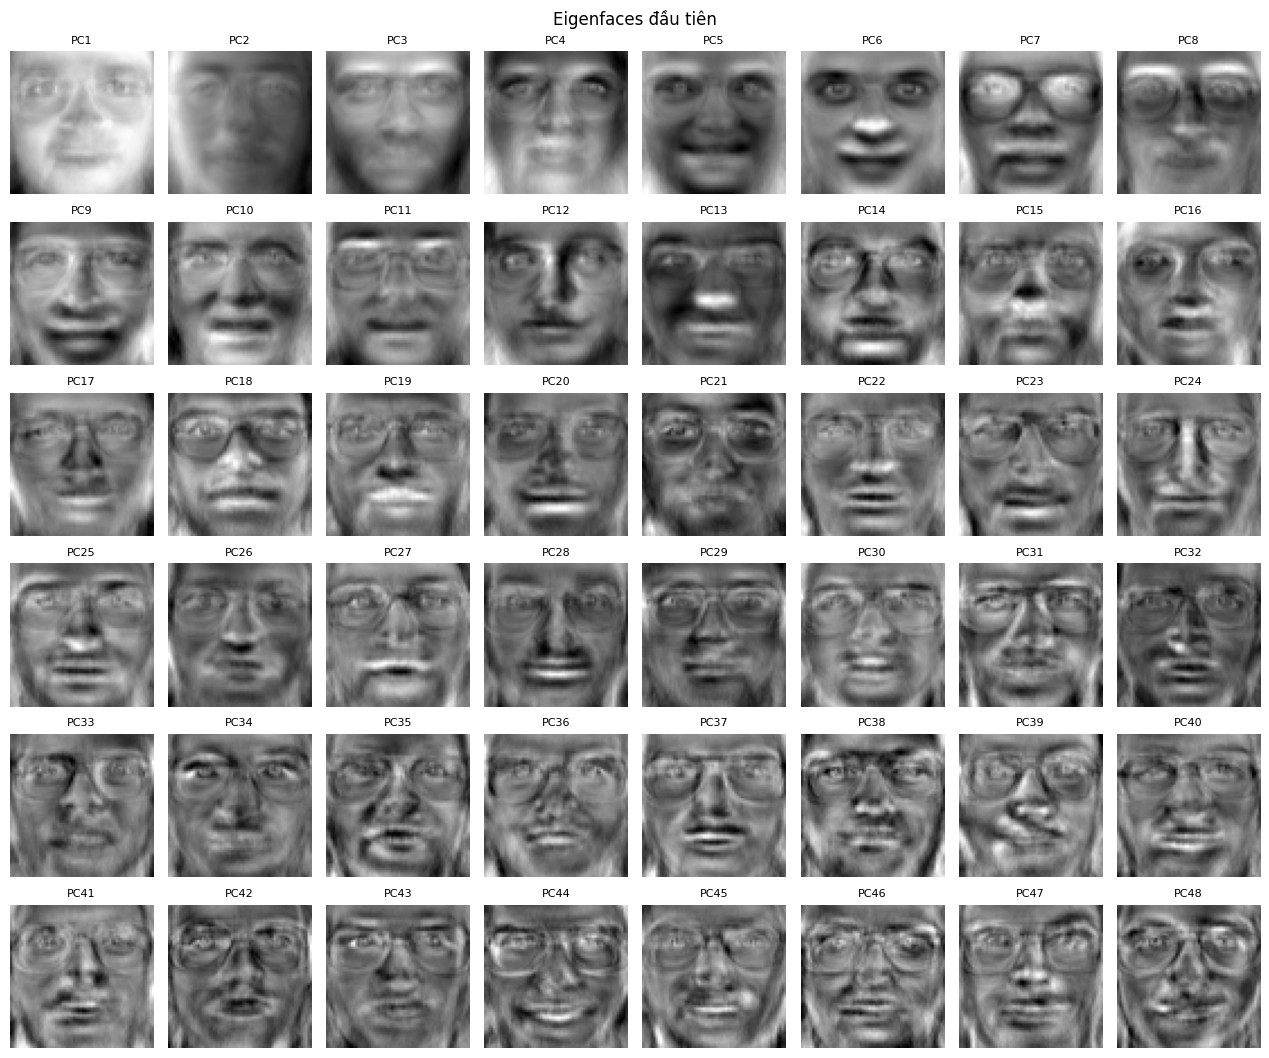

In [6]:
# 1. Tải tập ảnh khuôn mặt (400 ảnh, 64x64, giá trị trong [0, 1])
faces = fetch_olivetti_faces(shuffle=True, random_state=0)
X = faces.data                      # (400, 4096): mỗi ảnh MxM đã được trải thành vector M^2 chiều
M = faces.images.shape[1]           # 64
print("X shape:", X.shape)

# 2. Khuôn mặt trung bình (mean face)
mu = X.mean(axis=0)
plt.figure(figsize=(3, 3))
plt.imshow(mu.reshape(M, M), cmap="gray")
plt.title("Mean face")
plt.axis("off")
plt.show()

# 3. PCA -> eigenfaces
n_components = 48
pca = PCA(n_components=n_components, whiten=False, svd_solver="randomized", random_state=0)
pca.fit(X)                          # PCA tự trừ mean (pca.mean_ == mu)
eigenfaces = pca.components_        # (48, 4096)

rows, cols = 6, 8
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 1.8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(eigenfaces[i].reshape(M, M), cmap="gray")
    ax.set_title(f"PC{i+1}", fontsize=8)
    ax.axis("off")
plt.suptitle("Eigenfaces đầu tiên")
plt.tight_layout()
plt.show()

# 4. (Mở rộng) Chiếu một ảnh bất kỳ lên không gian eigenfaces và tái tạo
def reconstruct(path, ks=(5, 20, 48)):
    img = Image.open(path).convert("L").resize((M, M))
    x = np.asarray(img, dtype=np.float64).ravel() / 255.0
    fig, axes = plt.subplots(1, len(ks) + 1, figsize=(3 * (len(ks) + 1), 3))
    axes[0].imshow(x.reshape(M, M), cmap="gray"); axes[0].set_title("Gốc"); axes[0].axis("off")
    for ax, k in zip(axes[1:], ks):
        w = (x - mu) @ eigenfaces[:k].T          # tọa độ trong không gian k eigenfaces
        x_hat = mu + w @ eigenfaces[:k]          # tái tạo
        ax.imshow(x_hat.reshape(M, M), cmap="gray")
        ax.set_title(f"k = {k}"); ax.axis("off")
    plt.show()

Bài 3

Chọn một khuôn mặt trong tập. Chiếu nó vào k thành phần chính đầu tiên rồi TÁI TẠO lại, với k = 5, 20, 50, 100. Hiển thị
các ảnh tái tạo cạnh ảnh gốc.

Vẽ đường phương sai giải thích tích lũy (cumulative explained variance) theo số thành phần. Cần bao nhiêu thành phần
để giữ ~90% phương sai?

Viết vài câu: vì sao chỉ vài chục thành phần đã tái tạo khuôn mặt khá tốt, dù ảnh gốc có tới M2 chiều? Điều này nói gì về
sự dư thừa (redundancy) trong ảnh khuôn mặt?

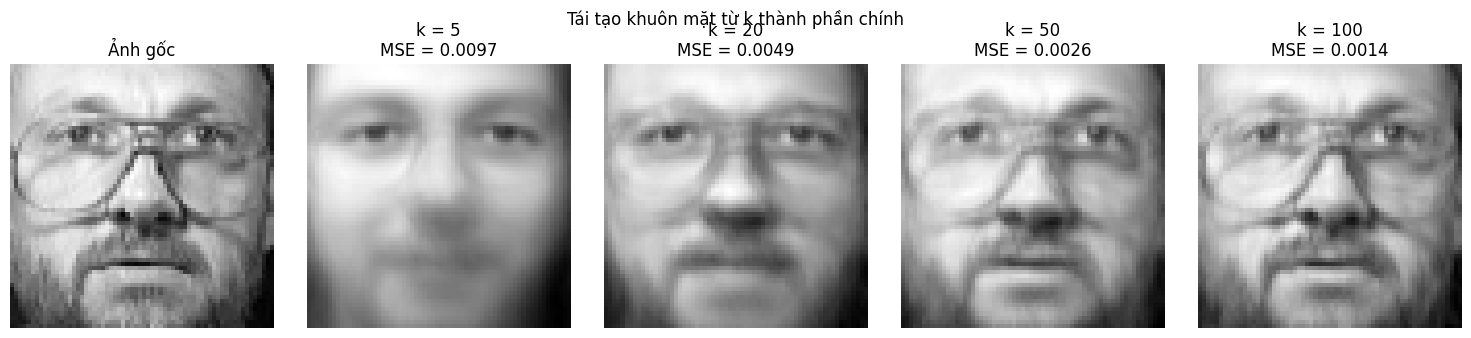

In [5]:
# --- Dữ liệu ---
faces = fetch_olivetti_faces(shuffle=True, random_state=0)
X = faces.data                       # (400, 4096)
M = faces.images.shape[1]            # 64

# --- PCA đầy đủ (giữ tối đa số thành phần để vẽ phương sai tích lũy) ---
pca = PCA(n_components=None, svd_solver="full")
pca.fit(X)
mu = pca.mean_

# --- 1. Chiếu và tái tạo một khuôn mặt với k = 5, 20, 50, 100 ---
idx = 0                              # đổi chỉ số để chọn khuôn mặt khác
x = X[idx]
ks = [5, 20, 50, 100]

fig, axes = plt.subplots(1, len(ks) + 1, figsize=(3 * (len(ks) + 1), 3.4))
axes[0].imshow(x.reshape(M, M), cmap="gray")
axes[0].set_title("Ảnh gốc")
axes[0].axis("off")

for ax, k in zip(axes[1:], ks):
    comps = pca.components_[:k]              # (k, 4096)
    w = (x - mu) @ comps.T                   # tọa độ k chiều
    x_hat = mu + w @ comps                   # tái tạo lại
    mse = np.mean((x - x_hat) ** 2)
    ax.imshow(x_hat.reshape(M, M), cmap="gray")
    ax.set_title(f"k = {k}\nMSE = {mse:.4f}")
    ax.axis("off")
plt.suptitle("Tái tạo khuôn mặt từ k thành phần chính")
plt.tight_layout()
plt.show()

bài 4

Một ảnh khuôn mặt 100×100 được biểu diễn thành vector. Không gian ảnh có bao nhiêu chiều? Nếu chỉ giữ k = 50 thành
phần chính, mỗi khuôn mặt được mô tả bằng bao nhiêu con số? Tỉ lệ giảm chiều là bao nhiêu?


Để nhận dạng, ta chiếu ảnh mới thành vector p rồi tính khoảng cách tới mỗi lớp khuôn mặt εk
2 = ‖p − pk‖
2
. Mô tả bằng
lời quy tắc quyết định: khi nào kết luận "là người k", khi nào kết luận "không phải khuôn mặt đã biết"? Vai trò của một
ngưỡng khoảng cách θc là gì?

Với một ảnh 100x100 thì không gian ảnh sẽ có 10000 chiều

Nếu chỉ giữ k =50 thành phần chính thì mỗi khuôn mặt dc mô tả bằng 50 con số, 50 hệ số chiếu lên 50 eigenfaces đầu tiên.

